# Synthetic Financial (PaySim): Pre-Authorization XGBoost

**Objective:** Rank transactions for human review before authorization using only request-time amount and type.
Notebook 03 documents data quality, field meanings, and the publisher's balance warning. This notebook compares an amount-and-type XGBoost candidate with simple baselines and an **offline-only** 12-feature diagnostic on the same timeline.

The historical project model used a random validation split, all four balances, the simulation hour, and the rule flag. Its PR-AUC of 0.9651 and its threshold of 0.971 are historical results, not launch targets. This run leaves that model and feature list unchanged.

In [1]:
import hashlib
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from sklearn.metrics import (auc, average_precision_score, confusion_matrix,
                            precision_recall_curve, roc_auc_score)
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.synthetic_financial import (
    HISTORICAL_FEATURES, PRE_AUTH_FEATURES, TRANSACTION_TYPES, load_paysim,
    paysim_path, prepare_pre_auth_features,
)

SEED = 42
N_JOBS = min(8, os.cpu_count() or 1)
TRAIN_END = 14 * 24
VALIDATION_END = 21 * 24
ALERTS_PER_1000 = 10

path = paysim_path(PROJECT_ROOT)
data = load_paysim(path, include_accounts=False)
with path.open("rb") as source:
    data_sha256 = hashlib.file_digest(source, "sha256").hexdigest()
print(f"Source: {path.relative_to(PROJECT_ROOT)}; SHA-256: {data_sha256}")

Source: data/raw/synthetic_financial/synthetic_financial.csv; SHA-256: 16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b


## 1. Split by complete simulation hours before fitting

Train on the first 14 days, tune the alert threshold on the following 7 days, and test on the remaining hours. There is no random shuffle or overlap in hours. Report row counts and fraud prevalence separately: traffic is uneven across time, and a random split hides that shift. The test is a later period in the **same simulation**, not an external dataset.

In [2]:
train = data.loc[data["step"].le(TRAIN_END)]
validation = data.loc[data["step"].gt(TRAIN_END) & data["step"].le(VALIDATION_END)]
test = data.loc[data["step"].gt(VALIDATION_END)]
splits = {"train": train, "validation": validation, "test": test}
assert sum(len(frame) for frame in splits.values()) == len(data)
assert all(frame["isFraud"].nunique() == 2 for frame in splits.values())
assert train["step"].max() < validation["step"].min() < test["step"].min()
assert validation["step"].max() < test["step"].min()
split_summary = pd.DataFrame.from_dict({
    label: {
        "first_hour": int(frame["step"].min()), "last_hour": int(frame["step"].max()),
        "rows": len(frame), "fraud_rows": int(frame["isFraud"].sum()),
        "fraud_prevalence": float(frame["isFraud"].mean()),
    }
    for label, frame in splits.items()
}, orient="index")
display(split_summary)
del data

,first_hour,last_hour,rows,fraud_rows,fraud_prevalence
train,1,336,4784775,3767,0.000787
validation,337,504,1279261,1854,0.001449
test,505,743,298584,2592,0.008681


## 2. Fit models and compare against baselines

**Scoring candidate:** XGBoost with raw amount and five fixed one-hot type flags. No scaling, fitted imputation, or amount clipping is needed. Unknown types or invalid amounts fail validation rather than becoming an all-zero feature row.

**Baselines:** A constant scorer shows the no-skill average precision; a type-only scorer ranks by fraud prevalence learned from the training rows only. The existing simulator flag is reported separately as a diagnostic, not treated as a score input.

**Historical-feature diagnostic:** A second XGBoost uses the original 12 inputs with the same tree configuration and split. It illustrates how easily the dataset can be scored with fields that a real decision cannot rely on. The performance gap covers the entire excluded feature set, not just one column. We do not export this diagnostic model.

Both XGBoost runs use a positive-class weight calculated on training rows only, and the same fixed hyperparameters. Scores are rankings, not calibrated real-world probabilities.

In [3]:
def prepare_diagnostic_features(frame):
    safe = prepare_pre_auth_features(frame)
    for name in ("step", "oldbalanceOrg", "newbalanceOrig",
                 "oldbalanceDest", "newbalanceDest", "isFlaggedFraud"):
        safe[name] = frame[name].to_numpy(dtype=np.float32)
    return safe.loc[:, HISTORICAL_FEATURES]


def fit_xgboost(features, target):
    model = XGBClassifier(
        n_estimators=500, max_depth=6, learning_rate=0.05,
        scale_pos_weight=float(target.eq(0).sum() / target.eq(1).sum()),
        eval_metric="aucpr", tree_method="hist", random_state=SEED, n_jobs=N_JOBS,
    )
    model.fit(features, target)
    return model


candidate = fit_xgboost(prepare_pre_auth_features(train), train["isFraud"])
diagnostic = fit_xgboost(prepare_diagnostic_features(train), train["isFraud"])
print(f"Training positive-class weight: {candidate.get_params()['scale_pos_weight']:.2f}")
assert tuple(candidate.get_booster().feature_names) == PRE_AUTH_FEATURES
assert tuple(diagnostic.get_booster().feature_names) == HISTORICAL_FEATURES
type_rates = train.groupby("type", observed=True)["isFraud"].mean()
assert set(type_rates.index) == set(TRANSACTION_TYPES)
display(type_rates.rename("training_fraud_rate").to_frame())

Training positive-class weight: 1269.18


,training_fraud_rate
type,
CASH_IN,0.000000
CASH_OUT,0.001117
DEBIT,0.000000
PAYMENT,0.000000
TRANSFER,0.004725


## 3. Choose and freeze the review threshold on validation only

Use an illustrative capacity of **10 alerts per 1,000 transactions**. Among thresholds within that validation budget, maximize fraud recall, then precision, then the threshold. Equal scores are kept together. This is a demonstration policy, not a bank-approved operating point; the later test alert rate may exceed the validation budget.

In [4]:
val_y = validation["isFraud"].to_numpy()
val_scores = candidate.predict_proba(prepare_pre_auth_features(validation))[:, 1]
val_precision, val_recall, thresholds = precision_recall_curve(val_y, val_scores)
sorted_scores = np.sort(val_scores)
alert_counts = len(sorted_scores) - np.searchsorted(sorted_scores, thresholds, side="left")
max_alerts = len(val_y) * ALERTS_PER_1000 // 1_000
feasible = pd.DataFrame({
    "threshold": thresholds, "precision": val_precision[:-1],
    "recall": val_recall[:-1], "alerts": alert_counts,
}).loc[alert_counts <= max_alerts]
if feasible.empty:
    raise ValueError("No non-empty alert set fits the validation capacity; do not publish a threshold")
chosen = feasible.sort_values(["recall", "precision", "threshold"], ascending=False).iloc[0]
threshold = float(chosen["threshold"])
assert np.count_nonzero(val_scores >= threshold) == int(chosen["alerts"])
print(f"Frozen threshold: {threshold:.8f} (alert if score >= threshold)")
print(f"Validation budget: {max_alerts:,}; selected alerts: {int(chosen['alerts']):,}")

Frozen threshold: 0.91918761 (alert if score >= threshold)
Validation budget: 12,792; selected alerts: 12,770


## 4. Evaluate on the later test window

**Average precision (AP)** is the primary ranking metric for this rare class. **Trapezoidal PR-AUC** is reported separately because interpolation differs, especially when many scores tie. **ROC-AUC** is a secondary ranking metric. The constant-score ranking reference has AP equal to fraud prevalence; don't interpret its interpolated PR-AUC.

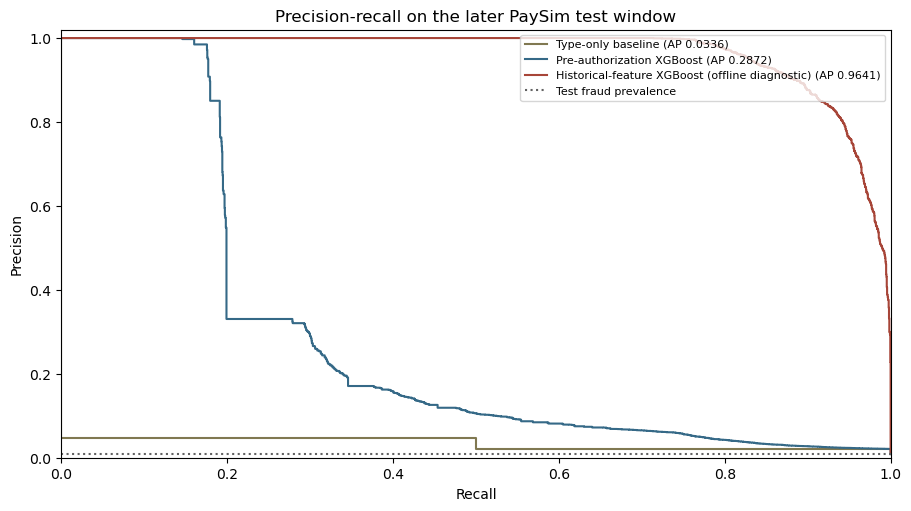

,average_precision,pr_auc_trapezoidal,roc_auc
model,,,
Constant score (no-skill reference),0.008681,NaN,0.500000
Type-only baseline,0.033568,0.278344,0.852263
Pre-authorization XGBoost,0.287158,0.296840,0.915447
Historical-feature XGBoost (offline diagnostic),0.964125,0.964124,0.999529


In [5]:
test_y = test["isFraud"].to_numpy()
test_scores = candidate.predict_proba(prepare_pre_auth_features(test))[:, 1]
test_rankings = {
    "Type-only baseline": test["type"].astype("string").map(type_rates.to_dict()).to_numpy(dtype=float),
    "Pre-authorization XGBoost": test_scores,
    "Historical-feature XGBoost (offline diagnostic)":
        diagnostic.predict_proba(prepare_diagnostic_features(test))[:, 1],
}
ranking_metrics = [{
    "model": "Constant score (no-skill reference)", "average_precision": float(test_y.mean()),
    "pr_auc_trapezoidal": np.nan, "roc_auc": 0.5,
}]
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for (name, scores), color in zip(test_rankings.items(), ["#807851", "#356987", "#a74538"]):
    precision, recall, _ = precision_recall_curve(test_y, scores)
    ap = average_precision_score(test_y, scores)
    ranking_metrics.append({
        "model": name, "average_precision": float(ap),
        "pr_auc_trapezoidal": float(auc(recall, precision)),
        "roc_auc": float(roc_auc_score(test_y, scores)),
    })
    ax.step(recall, precision, where="post", color=color, label=f"{name} (AP {ap:.4f})")
ax.axhline(test_y.mean(), color="#626262", linestyle=":", label="Test fraud prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision-recall on the later PaySim test window",
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="upper right", fontsize=8)
plt.show()
ranking_table = pd.DataFrame(ranking_metrics).set_index("model")
display(ranking_table.round(6))

In [6]:
def operating_metrics(y, alerts):
    tn, fp, fn, tp = (int(n) for n in confusion_matrix(y, alerts, labels=[0, 1]).ravel())
    return {
        "rows": len(y), "fraud_rows": tp + fn, "alerts": tp + fp,
        "true_negatives": tn, "false_alerts": fp, "missed_fraud": fn, "caught_fraud": tp,
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / (tp + fn) if tp + fn else 0.0,
        "f1": (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0,
        "alerts_per_1000": 1_000 * (tp + fp) / len(y),
    }


val_result = operating_metrics(val_y, val_scores >= threshold)
test_result = operating_metrics(test_y, test_scores >= threshold)
rule_result = operating_metrics(test_y, test["isFlaggedFraud"].eq(1))
display(pd.DataFrame({
    "Candidate validation": val_result, "Candidate later test": test_result,
    "Simulator flag only (later test)": rule_result,
}).round(6))
print("Test confusion matrix (rows actual, columns predicted; order 0, 1):")
print(confusion_matrix(test_y, test_scores >= threshold, labels=[0, 1]))

outcomes = test.loc[:, ["type", "isFraud"]].assign(alert=test_scores >= threshold)
outcomes["caught"] = outcomes["alert"] & outcomes["isFraud"].eq(1)
type_outcomes = outcomes.groupby("type", observed=True).agg(
    rows=("isFraud", "size"), fraud_rows=("isFraud", "sum"), alerts=("alert", "sum"),
    caught_fraud=("caught", "sum"),
)
type_outcomes["missed_fraud"] = type_outcomes["fraud_rows"] - type_outcomes["caught_fraud"]
type_outcomes["false_alerts"] = type_outcomes["alerts"] - type_outcomes["caught_fraud"]
display(type_outcomes)

,Candidate validation,Candidate later test,Simulator flag only (later test)
rows,1.279261e+06,298584.000000,298584.000000
fraud_rows,1.854000e+03,2592.000000,2592.000000
alerts,1.277000e+04,3291.000000,10.000000
true_negatives,1.265297e+06,293516.000000,295992.000000
false_alerts,1.211000e+04,2476.000000,0.000000
missed_fraud,1.194000e+03,1777.000000,2582.000000
caught_fraud,6.600000e+02,815.000000,10.000000
precision,5.168400e-02,0.247645,1.000000
recall,3.559870e-01,0.314429,0.003858
f1,9.026300e-02,0.277070,0.007686


Test confusion matrix (rows actual, columns predicted; order 0, 1):
[[293516   2476]
 [  1777    815]]


,rows,fraud_rows,alerts,caught_fraud,missed_fraud,false_alerts
type,,,,,,
CASH_IN,68121,0,0,0,0,0
CASH_OUT,96019,1296,632,519,777,113
DEBIT,2441,0,0,0,0,0
PAYMENT,103976,0,0,0,0,0
TRANSFER,28027,1296,2659,296,1000,2363


## 5. Package the research candidate and verify scoring parity

The exported candidate is not activated in TiDB. Input is the raw transaction amount in a consistent currency and the transaction type. The five indicators are derived, not separate database inputs. Invalid inputs must be rejected or quarantined, never replaced with zeros. A transaction ID is needed to link a decision to a record, but is not a model feature.

This is one synthetic scenario. Changes in fraud prevalence and transaction mix can change the workload at a fixed threshold. Before live use, confirm input timing and currency at the API or database boundary, validate on actual out-of-time data, and set review capacity with analysts. No automatic blocking is implied.

In [7]:
folder = PROJECT_ROOT / "artifacts" / "models"
folder.mkdir(parents=True, exist_ok=True)
model_file = folder / "synthetic_financial_pre_auth_xgboost.json"
contract_file = folder / "synthetic_financial_pre_auth_contract.json"
model_version = "Synthetic_PreAuth_XGBoost_v1.0"

sample = test.iloc[:128]
notebook_scores = candidate.predict_proba(prepare_pre_auth_features(sample))[:, 1]
request_rows = sample.loc[:, ["amount", "type"]].copy()
request_rows["type"] = request_rows["type"].astype("string").str.lower().str.replace("_", "-")
request_features = prepare_pre_auth_features(request_rows)
assert tuple(request_features.columns) == PRE_AUTH_FEATURES
assert request_features.loc[:, list(PRE_AUTH_FEATURES[1:])].sum(axis=1).eq(1).all()

candidate.save_model(model_file)
reloaded = XGBClassifier()
reloaded.load_model(model_file)
assert tuple(reloaded.get_booster().feature_names) == PRE_AUTH_FEATURES
np.testing.assert_array_equal(reloaded.predict_proba(request_features)[:, 1], notebook_scores)

contract = {
    "dataset": "synthetic_financial",
    "model_version": model_version,
    "status": "offline_candidate",
    "model_file": model_file.name,
    "model_sha256": hashlib.sha256(model_file.read_bytes()).hexdigest(),
    "data_sha256": data_sha256,
    "versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__},
    "raw_inputs": {"amount": "finite non-negative amount in the training currency",
                   "type": list(TRANSACTION_TYPES)},
    "preprocessor": "src.synthetic_financial.prepare_pre_auth_features",
    "feature_order": list(PRE_AUTH_FEATURES),
    "training_parameters": {key: candidate.get_params()[key] for key in (
        "n_estimators", "max_depth", "learning_rate", "scale_pos_weight",
        "eval_metric", "tree_method", "random_state", "n_jobs",
    )},
    "decision": {"operator": ">=", "threshold": threshold, "positive_action": "review",
                 "validation_target_alerts_per_1000": ALERTS_PER_1000},
    "split_by_simulated_hour": split_summary.to_dict(orient="index"),
    "validation": val_result,
    "test": {**test_result, **{
        key: float(value) for key, value in ranking_table.loc["Pre-authorization XGBoost"].items()
    }},
}
contract_file.write_text(json.dumps(contract, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print(f"Scoring parity verified on {len(sample)} test transactions after serialization.")
print(f"Saved: {model_file.relative_to(PROJECT_ROOT)}")
print(f"Saved: {contract_file.relative_to(PROJECT_ROOT)}")

Scoring parity verified on 128 test transactions after serialization.
Saved: artifacts/models/synthetic_financial_pre_auth_xgboost.json
Saved: artifacts/models/synthetic_financial_pre_auth_contract.json


## Conclusion from the saved run

- On the same later test window, average precision was **0.0336** for the type-only baseline, **0.2872** for the amount-and-type candidate, and **0.9641** for the offline diagnostic. The last number is not a pre-authorization result.
- The frozen threshold caught **815 of 2,592** fraud cases and raised **2,476** false alerts. The later window reached **11.02 alerts per 1,000**, above the illustrative validation budget of 10. A fixed threshold does not guarantee a fixed workload.
- Use the candidate only for an offline or demo review queue. It misses most fraud at this operating point. A real release needs verified request-time data, independently validated features, and an agreed review policy.